# CS 370 A3 Q2
Numerical solution of $y'=-2ty^2$, $y(0)=1$ using Forward Euler and Explicit Midpoint.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## (a) Dynamics and exact solution

In [2]:
def Dynamics(t, y):
    return -2.0 * t * (y ** 2)

def ExactVal(t):
    return 1.0 / (1.0 + t**2)

## (b) Forward Euler

In [3]:
def ForwardEuler(t0, tfinal, N, y0):
    h = (tfinal - t0) / N
    y = np.zeros(N + 1, dtype=float)
    y[0] = y0
    t = t0
    for n in range(N):
        y[n+1] = y[n] + h * Dynamics(t, y[n])
        t += h
    return y

## (c) Effect of timestep size (Forward Euler)

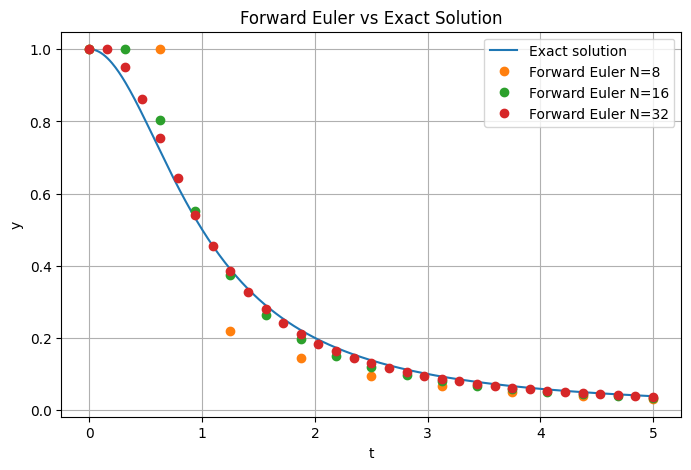

In [4]:
t0, tfinal, y0 = 0.0, 5.0, 1.0
N_list = [8, 16, 32]

plt.figure(figsize=(8,5))
t_exact = np.linspace(t0, tfinal, 500)
plt.plot(t_exact, ExactVal(t_exact), label="Exact solution")

for N in N_list:
    t = np.linspace(t0, tfinal, N+1)
    y_fe = ForwardEuler(t0, tfinal, N, y0)
    plt.plot(t, y_fe, linestyle='None', marker='o', label=f"Forward Euler N={N}")

plt.xlabel("t")
plt.ylabel("y")
plt.title("Forward Euler vs Exact Solution")
plt.legend()
plt.grid(True)
plt.show()

## (d) Explicit Midpoint

In [5]:
def ExplicitMidpoint(t0, tfinal, N, y0):
    h = (tfinal - t0) / N
    y = np.zeros(N + 1, dtype=float)
    y[0] = y0
    t = t0
    for n in range(N):
        k1 = Dynamics(t, y[n])
        k2 = Dynamics(t + h/2.0, y[n] + h*k1/2.0)
        y[n+1] = y[n] + h*k2
        t += h
    return y

## (e) Compare Forward Euler and Explicit Midpoint (N=16)

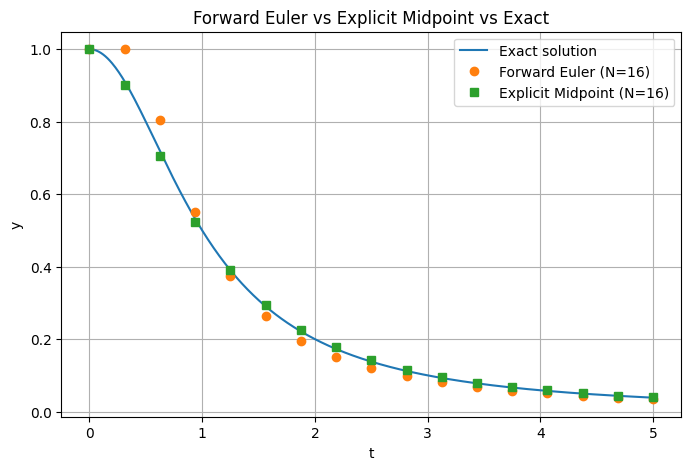

In [6]:
N = 16
t = np.linspace(t0, tfinal, N+1)
y_fe = ForwardEuler(t0, tfinal, N, y0)
y_mid = ExplicitMidpoint(t0, tfinal, N, y0)

plt.figure(figsize=(8,5))
plt.plot(np.linspace(t0, tfinal, 500), ExactVal(np.linspace(t0, tfinal, 500)), label="Exact solution")
plt.plot(t, y_fe, linestyle='None', marker='o', label="Forward Euler (N=16)")
plt.plot(t, y_mid, linestyle='None', marker='s', label="Explicit Midpoint (N=16)")
plt.xlabel("t")
plt.ylabel("y")
plt.title("Forward Euler vs Explicit Midpoint vs Exact")
plt.legend()
plt.grid(True)
plt.show()

## (f) Forward Euler global error table

In [7]:
print("i\terror\terror_ratio")

prev_err = None
for i in range(9):   # i = 0,1,...,8
    N = 8 * (2**i)
    yN = ForwardEuler(0.0, 5.0, N, 1.0)
    err = abs(yN[-1] - ExactVal(5.0))

    if prev_err is None:
        print(f"{i}\t{err:.12e}\t-")
    else:
        # ratio = err(h/2) / err(h)
        print(f"{i}\t{err:.12e}\t{err/prev_err:.12f}")

    prev_err = err

i	error	error_ratio
0	8.367482094491e-03	-
1	4.276283604617e-03	0.511059785528
2	2.170133651379e-03	0.507481227166
3	1.092061472471e-03	0.503223141016
4	5.476975057239e-04	0.501526259767
5	2.742577163080e-04	0.500746695835
6	1.372302843587e-04	0.500369820788
7	6.864040621313e-05	0.500184099551
8	3.432650812780e-05	0.500091855826


The error ratios approach approximately 0.5 as the timestep is halved, which is consistent with first-order global error \(O(h)\) for Forward Euler.

The error ratios approach approximately 0.5, consistent with first-order global error $O(h)$.

## (g) Explicit Midpoint global error table

In [8]:
print("i\terror\terror_ratio")
prev_err = None
for i in range(9):
    N = 8 * (2**i)
    yN = ExplicitMidpoint(0.0, 5.0, N, 1.0)
    err = abs(yN[-1] - ExactVal(5.0))
    if prev_err is None:
        print(f"{i}\t{err:.12e}\t-")
    else:
        print(f"{i}\t{err:.12e}\t{err/prev_err:.12f}")
    prev_err = err

i	error	error_ratio
0	4.006572965132e-03	-
1	7.258979717563e-04	0.181176775782
2	1.523207666417e-04	0.209837708009
3	3.522994062158e-05	0.231287836835
4	8.490897437242e-06	0.241013674376
5	2.085340765901e-06	0.245597215290
6	5.167906882778e-07	0.247820738331
7	1.286373851050e-07	0.248915833863
8	3.208978875680e-08	0.249459274460


The error ratios approach approximately 0.25, consistent with second-order global error $O(h^2)$.